In [10]:
!pip install -q numpy matplotlib scipy scikit-image pandas

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.ndimage import (
    uniform_filter,
    median_filter
)

from skimage import data
from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

np.random.seed(42)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


Dimensões: (512, 512)
Valor mínimo: 0.0
Valor máximo: 1.0


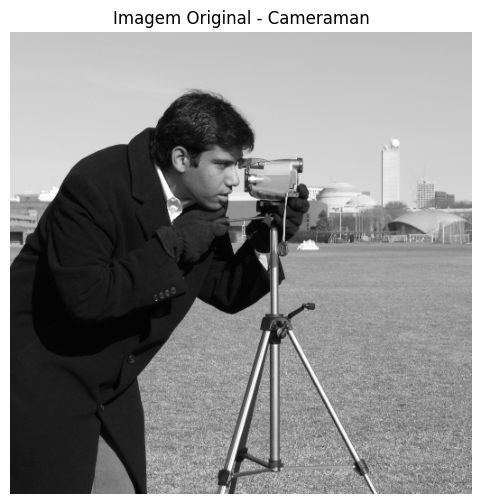

In [12]:
imagem_original = data.camera()

imagem_original = imagem_original.astype(np.float32) / 255.0

print("Dimensões:", imagem_original.shape)
print("Valor mínimo:", imagem_original.min())
print("Valor máximo:", imagem_original.max())

plt.figure(figsize=(6, 6))
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Imagem Original - Cameraman")
plt.axis("off")
plt.show()

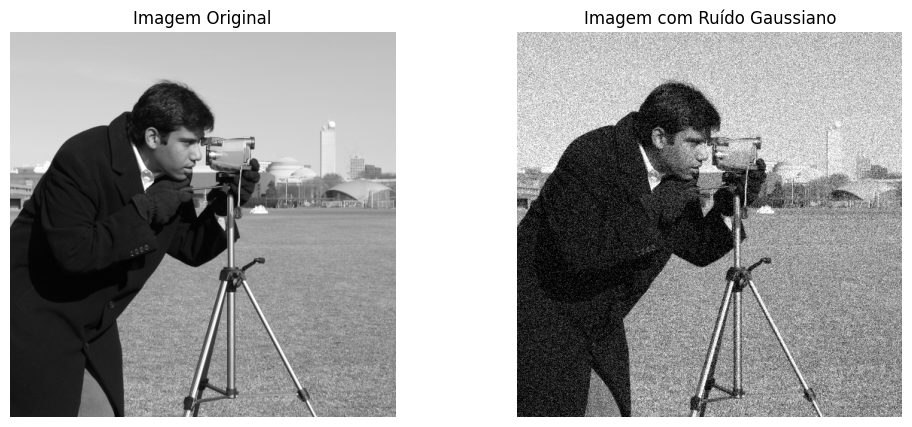

In [13]:
def adicionar_ruido_gaussiano(imagem, variancia=0.01):

    media = 0

    desvio_padrao = np.sqrt(variancia)

    ruido = np.random.normal(
        media,
        desvio_padrao,
        imagem.shape
    )

    imagem_ruidosa = imagem + ruido

    imagem_ruidosa = np.clip(
        imagem_ruidosa,
        0,
        1
    )

    return imagem_ruidosa


imagem_gaussiana = adicionar_ruido_gaussiano(
    imagem_original,
    variancia=0.01
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagem_gaussiana, cmap="gray", vmin=0, vmax=1)
plt.title("Imagem com Ruído Gaussiano")
plt.axis("off")

plt.show()

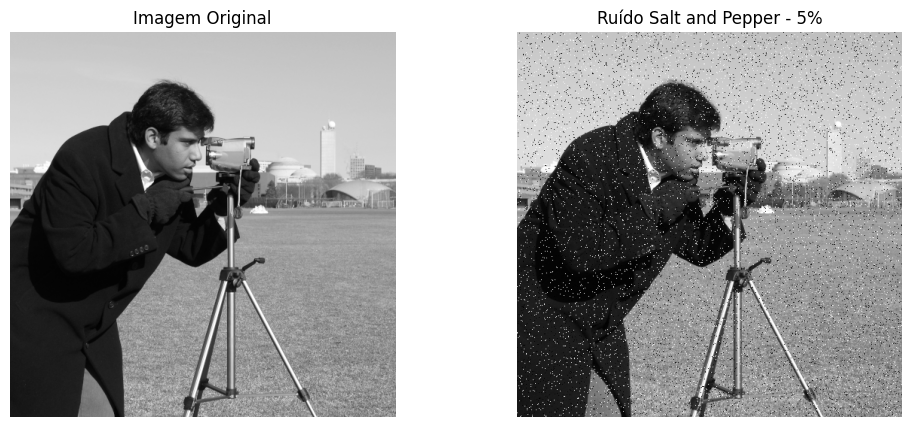

In [14]:
def adicionar_ruido_salt_pepper(imagem, quantidade=0.05):

    imagem_ruidosa = imagem.copy()

    total_pixels = imagem.size

    quantidade_ruido = int(
        total_pixels * quantidade
    )

    coordenadas = np.random.choice(
        total_pixels,
        quantidade_ruido,
        replace=False
    )

    metade = quantidade_ruido // 2

    imagem_flat = imagem_ruidosa.ravel()

    imagem_flat[coordenadas[:metade]] = 0

    imagem_flat[coordenadas[metade:]] = 1

    return imagem_flat.reshape(imagem.shape)


imagem_salt_pepper = adicionar_ruido_salt_pepper(
    imagem_original,
    quantidade=0.05
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagem_salt_pepper, cmap="gray", vmin=0, vmax=1)
plt.title("Ruído Salt and Pepper - 5%")
plt.axis("off")

plt.show()

In [16]:
def construir_grafo(imagem, raio=2,
                    sigma_espacial=2.0,
                    sigma_intensidade=0.12):

    imagem = imagem.astype(np.float32)

    altura, largura = imagem.shape

    soma_ponderada = np.zeros_like(imagem)
    soma_pesos = np.zeros_like(imagem)

    for dy in range(-raio, raio + 1):

        for dx in range(-raio, raio + 1):

            if dy == 0 and dx == 0:
                continue

            distancia = np.sqrt(dx**2 + dy**2)

            peso_espacial = np.exp(
                -(distancia**2) /
                (2 * sigma_espacial**2)
            )

            deslocada = np.roll(
                imagem,
                shift=(dy, dx),
                axis=(0, 1)
            )


            mascara = np.ones_like(imagem, dtype=bool)

            if dy > 0:
                mascara[:dy, :] = False
            elif dy < 0:
                mascara[dy:, :] = False

            if dx > 0:
                mascara[:, :dx] = False
            elif dx < 0:
                mascara[:, dx:] = False

            diferenca = (imagem - deslocada) ** 2

            diferenca_local = uniform_filter(
                diferenca,
                size=3,
                mode="nearest"
            )

            peso_intensidade = np.exp(
                -diferenca_local /
                (2 * sigma_intensidade**2)
            )

            peso = (
                peso_espacial *
                peso_intensidade
            )

            peso *= mascara

            soma_ponderada += peso * deslocada

            soma_pesos += peso

    peso_proprio = 1.0

    soma_ponderada += peso_proprio * imagem
    soma_pesos += peso_proprio

    return soma_ponderada, soma_pesos

In [17]:
def aplicar_filtro_grafo(imagem,
                         raio=2,
                         sigma_espacial=2.0,
                         sigma_intensidade=0.12):

    numerador, denominador = construir_grafo(
        imagem,
        raio=raio,
        sigma_espacial=sigma_espacial,
        sigma_intensidade=sigma_intensidade
    )

    imagem_filtrada = numerador / np.maximum(
        denominador,
        1e-8
    )

    return np.clip(imagem_filtrada, 0, 1)

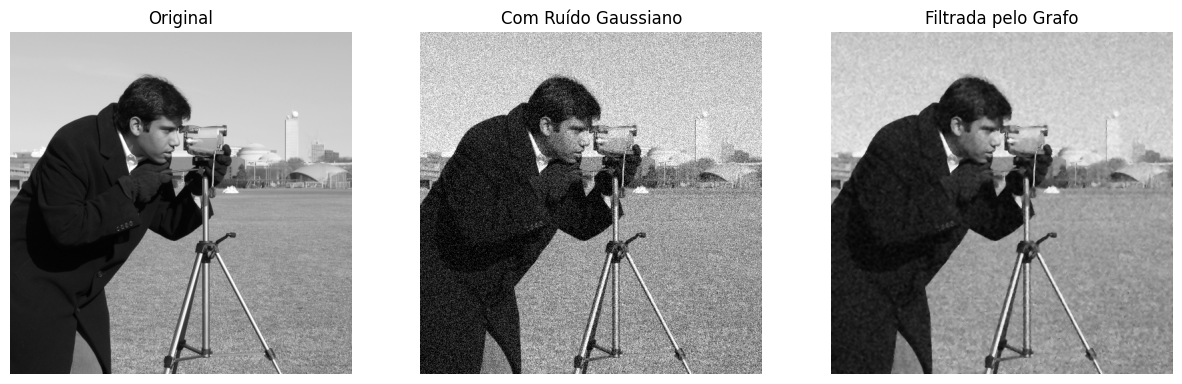

In [18]:
imagem_gaussiana_filtrada = aplicar_filtro_grafo(
    imagem_gaussiana,
    raio=2,
    sigma_espacial=2.0,
    sigma_intensidade=0.12
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagem_gaussiana, cmap="gray", vmin=0, vmax=1)
plt.title("Com Ruído Gaussiano")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_gaussiana_filtrada, cmap="gray", vmin=0, vmax=1)
plt.title("Filtrada pelo Grafo")
plt.axis("off")

plt.show()

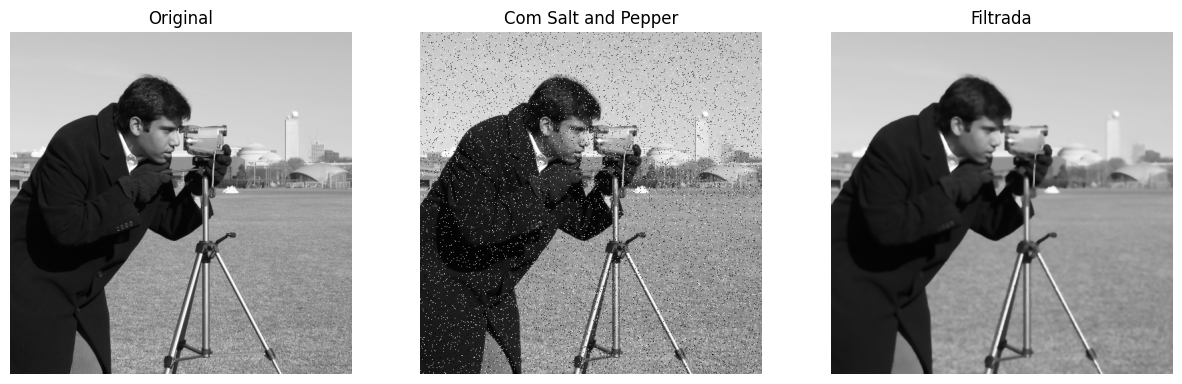

In [19]:
imagem_sp_preprocessada = median_filter(
    imagem_salt_pepper,
    size=3
)

imagem_sp_filtrada = aplicar_filtro_grafo(
    imagem_sp_preprocessada,
    raio=2,
    sigma_espacial=2.0,
    sigma_intensidade=0.15
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagem_salt_pepper, cmap="gray", vmin=0, vmax=1)
plt.title("Com Salt and Pepper")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagem_sp_filtrada, cmap="gray", vmin=0, vmax=1)
plt.title("Filtrada")
plt.axis("off")

plt.show()

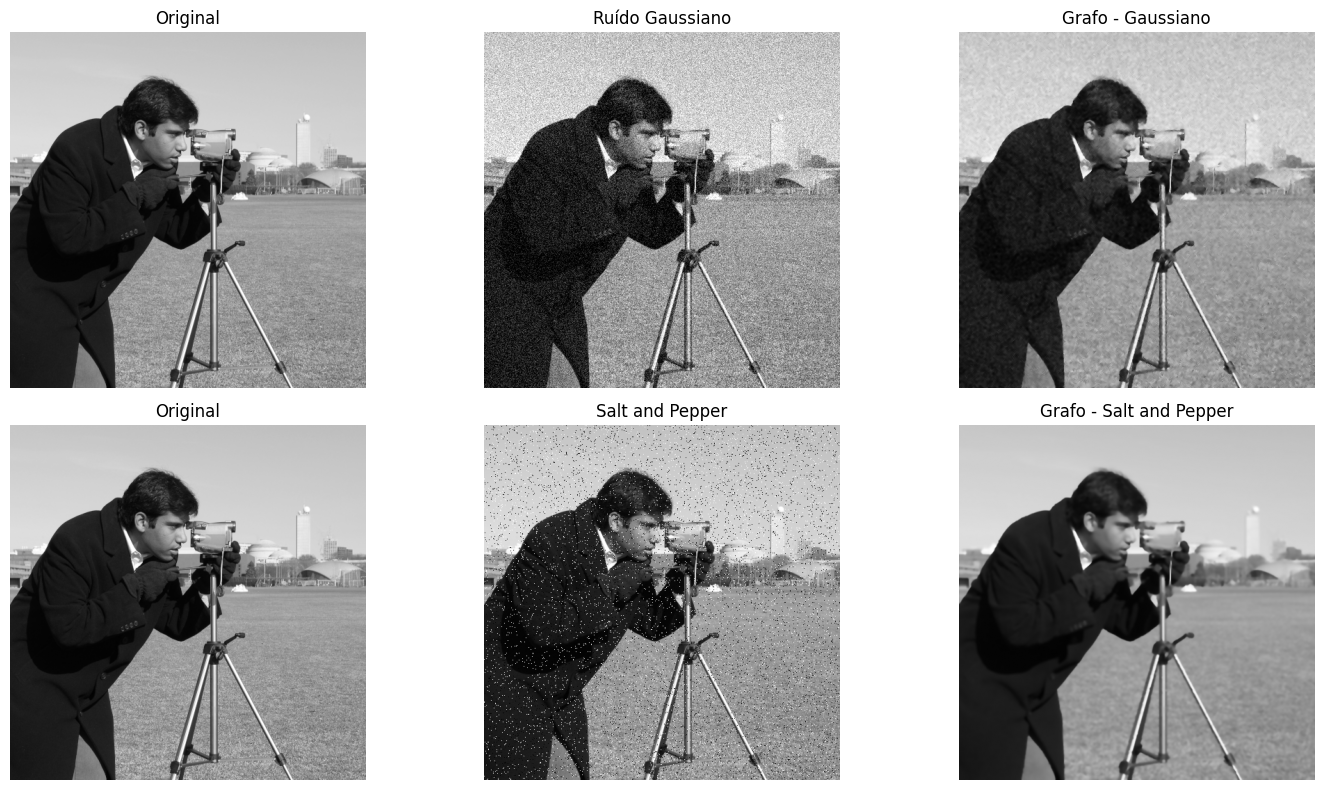

In [20]:
imagem_mediana_gaussiana = median_filter(
    imagem_gaussiana,
    size=3
)

imagem_mediana_sp = median_filter(
    imagem_salt_pepper,
    size=3
)

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(imagem_gaussiana, cmap="gray", vmin=0, vmax=1)
plt.title("Ruído Gaussiano")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(imagem_gaussiana_filtrada, cmap="gray", vmin=0, vmax=1)
plt.title("Grafo - Gaussiano")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=1)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(imagem_salt_pepper, cmap="gray", vmin=0, vmax=1)
plt.title("Salt and Pepper")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(imagem_sp_filtrada, cmap="gray", vmin=0, vmax=1)
plt.title("Grafo - Salt and Pepper")
plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
def calcular_metricas(referencia, resultado):

    mse = mean_squared_error(
        referencia,
        resultado
    )

    rmse = np.sqrt(mse)

    psnr = peak_signal_noise_ratio(
        referencia,
        resultado,
        data_range=1.0
    )

    ssim = structural_similarity(
        referencia,
        resultado,
        data_range=1.0
    )

    return {
        "MSE": mse,
        "RMSE": rmse,
        "PSNR": psnr,
        "SSIM": ssim
    }

In [22]:
resultados = []

imagens_teste = {
    "Gaussiana - Ruidosa": imagem_gaussiana,
    "Gaussiana - Grafo": imagem_gaussiana_filtrada,
    "Gaussiana - Mediana": imagem_mediana_gaussiana,
    "Salt Pepper - Ruidosa": imagem_salt_pepper,
    "Salt Pepper - Grafo": imagem_sp_filtrada,
    "Salt Pepper - Mediana": imagem_mediana_sp
}

for nome, imagem in imagens_teste.items():

    metricas = calcular_metricas(
        imagem_original,
        imagem
    )

    metricas["Método"] = nome

    resultados.append(metricas)


tabela = pd.DataFrame(resultados)

tabela = tabela[
    ["Método", "MSE", "RMSE", "PSNR", "SSIM"]
]

display(tabela.round(4))

,Método,MSE,RMSE,PSNR,SSIM
0,Gaussiana - Ruidosa,0.0090,0.0951,20.4349,0.2956
1,Gaussiana - Grafo,0.0015,0.0384,28.3181,0.6762
2,Gaussiana - Mediana,0.0027,0.0518,25.7182,0.4936
3,Salt Pepper - Ruidosa,0.0165,0.1285,17.8213,0.3627
4,Salt Pepper - Grafo,0.0013,0.0362,28.8175,0.8091
5,Salt Pepper - Mediana,0.0010,0.0310,30.1631,0.8645


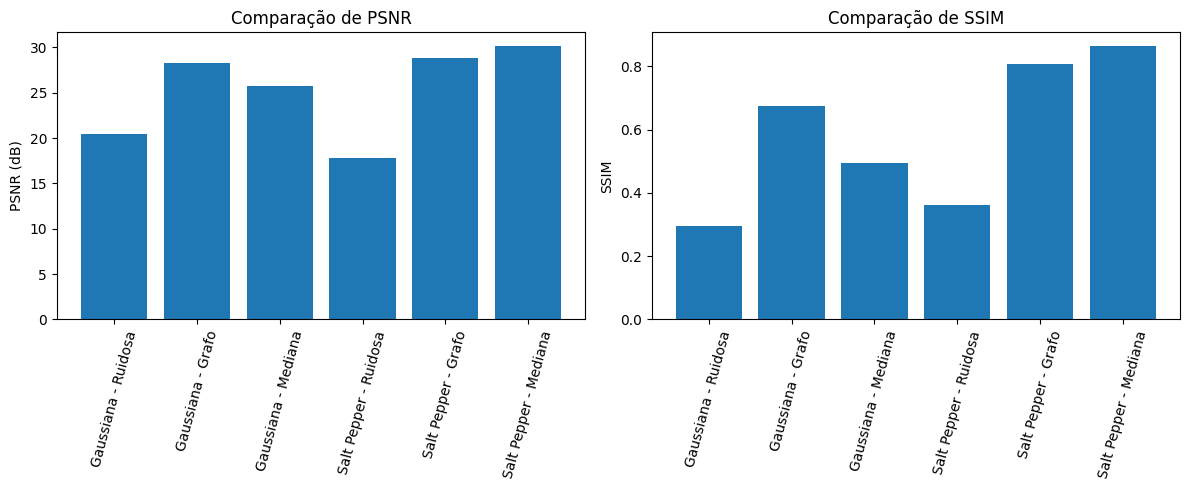

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.bar(
    tabela["Método"],
    tabela["PSNR"]
)

plt.title("Comparação de PSNR")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=75)

plt.subplot(1, 2, 2)

plt.bar(
    tabela["Método"],
    tabela["SSIM"]
)

plt.title("Comparação de SSIM")
plt.ylabel("SSIM")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()